In [45]:
import pandas as pd
from pathlib import Path

data_path = Path("../01_Data/raw/Beaute_Cachee_Sales_CRM/raw")

customers = pd.read_csv(data_path / "customers.csv")
products = pd.read_csv(data_path / "products.csv")
orders = pd.read_csv(data_path / "orders.csv")
order_items = pd.read_csv(data_path / "order_items.csv")
support_tickets = pd.read_csv(data_path / "support_tickets.csv")
satisfaction_surveys = pd.read_csv(data_path / "satisfaction_surveys.csv")

customers.head()

,customer_id,first_name,last_name,email,phone,customer_created_at,customer_creation_source,country,city,acquisition_channel,email_marketing_consent
0,C00001,Hugo,Laurent,customer00001@example.com,NaN,2024-06-20 11:00:00,Website Registration,France,Paris,Paid Social,Yes
1,C00002,Alice,Laurent,customer00002@example.com,NaN,2023-11-07 07:00:00,Website Registration,France,Paris,Organic Search,No
2,C00003,Camille,Garcia,customer00003@example.com,TEST-PHONE-00003,2025-10-08 22:11:56,Boutique,Belgium,Brussels,Paid Social,No
3,C00004,Emma,Lefebvre,customer00004@example.com,NaN,2025-11-26 08:46:13,Guest Checkout,Switzerland,Geneva,Paid Social,No
4,C00005,Emma,Dubois,customer00005@example.com,NaN,2025-12-13 01:32:27,Guest Checkout,Switzerland,Geneva,Referral,No


In [46]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               5020 non-null   object
 1   first_name                5020 non-null   object
 2   last_name                 5020 non-null   object
 3   email                     4727 non-null   object
 4   phone                     3217 non-null   object
 5   customer_created_at       5005 non-null   object
 6   customer_creation_source  5020 non-null   object
 7   country                   5020 non-null   object
 8   city                      5020 non-null   object
 9   acquisition_channel       5020 non-null   object
 10  email_marketing_consent   5020 non-null   object
dtypes: object(11)
memory usage: 431.5+ KB


### Observations initiales — customers

- La table contient 5 020 lignes et 11 colonnes.
- Les 11 colonnes sont actuellement de type object.
- Des valeurs manquantes sont présentes dans email (293),
  phone (1 803) et customer_created_at (15).
- La colonne customer_created_at devra être convertie en datetime.
- L’unicité de customer_id reste à vérifier.

Ces constats portent sur les données brutes, avant suppression des doublons.

# Beauté Cachée — Sales & CRM
## Préparation et contrôle de la qualité des données

**Période étudiée :** janvier–décembre 2025  
**Source :** base entièrement synthétique, créée pour ce projet.

### Objectif
Préparer une base fiable pour analyser les ventes et la performance
du service client à partir des KPI définis dans le projet.

### Plan de travail

1. Importation et exploration initiale
2. Nettoyage des six tables
3. Vérification des relations entre les tables
4. Validation et export des données nettoyées

### Jalons

- J1 — Les six tables sont importées et leur structure est examinée.
- J2 — Les doublons, valeurs manquantes, formats et anomalies sont traités.
- J3 — Les identifiants et les relations entre les tables sont vérifiés.
- J4 — Les données nettoyées sont prêtes pour l’analyse Sales & CRM.

### 1.3 — Vue d’ensemble des six tables

In [47]:
# Regrouper les six tables pour faciliter les contrôles
tables = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
    "support_tickets": support_tickets,
    "satisfaction_surveys": satisfaction_surveys
}

# Présenter le nombre de lignes et de colonnes de chaque table
overview = pd.DataFrame([
    {
        "Table": name,
        "Nombre de lignes": df.shape[0],
        "Nombre de colonnes": df.shape[1]
    }
    for name, df in tables.items()
])

overview

,Table,Nombre de lignes,Nombre de colonnes
0,customers,5020,11
1,products,202,5
2,orders,10030,7
3,order_items,15045,9
4,support_tickets,2010,10
5,satisfaction_surveys,804,4


In [48]:
# Examiner la structure des tables restantes
for name, df in tables.items():
    if name != "customers":
        print(f"\n--- {name} ---")
        df.info()


--- products ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    202 non-null    object
 1   product_name  202 non-null    object
 2   category      202 non-null    object
 3   collection    202 non-null    object
 4   list_price    202 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 8.0+ KB

--- orders ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10030 entries, 0 to 10029
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   order_id                10030 non-null  object
 1   customer_id             10030 non-null  object
 2   order_date              10030 non-null  object
 3   order_status            10030 non-null  object
 4   sales_channel           10030 non-null  object
 5   promised_delivery_date  7803 non-null   o

### Bilan de la phase 1

- Les six tables sont importées : 33 111 lignes au total.
- Toutes les colonnes de dates sont actuellement de type object.
- Les montants, quantités et scores sont reconnus comme numériques.
- Aucun manque n’est détecté dans products, order_items
  et satisfaction_surveys.
- Des valeurs manquantes sont présentes dans customers,
  orders et support_tickets.
- Les dates de livraison manquantes devront être examinées selon
  sales_channel et order_status.
- Les valeurs manquantes de support_tickets devront être examinées
  selon ticket_status et contact_reason.
- L’absence de valeurs manquantes ne garantit pas la validité des données.

**Jalon J1 atteint :** les six tables sont chargées et leur structure
est examinée.

## Phase 2 — Nettoyage des données

### 2.1 — Table customers
#### 2.1.1 — Identification des doublons

Distinguer les lignes entièrement identiques des enregistrements
partageant le même customer_id.

In [49]:
# Compter les lignes entièrement identiques après la première occurrence
print("Doublons complets :", customers.duplicated().sum())

# Compter les répétitions de customer_id après la première occurrence
print(
    "Répétitions de customer_id :",
    customers["customer_id"].duplicated().sum()
)

# Afficher toutes les occurrences des identifiants répétés
customers.loc[
    customers["customer_id"].duplicated(keep=False)
].sort_values("customer_id").head(10)

Doublons complets : 20
Répétitions de customer_id : 20


,customer_id,first_name,last_name,email,phone,customer_created_at,customer_creation_source,country,city,acquisition_channel,email_marketing_consent
279,C00280,Anna,Petit,NaN,NaN,2025-06-22 23:56:07,Boutique,France,Lyon,Organic Search,Unknown
5012,C00280,Anna,Petit,NaN,NaN,2025-06-22 23:56:07,Boutique,France,Lyon,Organic Search,Unknown
504,C00505,Lucas,Michel,customer00505@example.com,TEST-PHONE-00505,2023-06-23 06:00:00,Website Registration,France,Paris,Referral,Yes
5006,C00505,Lucas,Michel,customer00505@example.com,TEST-PHONE-00505,2023-06-23 06:00:00,Website Registration,France,Paris,Referral,Yes
1012,C01013,Clara,Moreau,NaN,NaN,2025-03-21 14:58:25,Boutique,France,Lyon,Referral,Unknown
5017,C01013,Clara,Moreau,NaN,NaN,2025-03-21 14:58:25,Boutique,France,Lyon,Referral,Unknown
1308,C01309,Louise,Lefebvre,customer01309@example.com,TEST-PHONE-01309,2025-12-02 12:17:53,Boutique,France,Nantes,Email,No
5015,C01309,Louise,Lefebvre,customer01309@example.com,TEST-PHONE-01309,2025-12-02 12:17:53,Boutique,France,Nantes,Email,No
1423,C01424,Alice,Laurent,customer01424@example.com,NaN,2025-06-05 02:37:39,Guest Checkout,France,Paris,Organic Search,No
5008,C01424,Alice,Laurent,customer01424@example.com,NaN,2025-06-05 02:37:39,Guest Checkout,France,Paris,Organic Search,No


#### 2.1.2 — Suppression des doublons complets

20 lignes entièrement identiques ont été identifiées.
Elles expliquent toutes les répétitions de customer_id.

Décision : conserver une seule occurrence de chaque ligne identique.

In [50]:
# Supprimer les doublons complets et réinitialiser l’index
customers = customers.drop_duplicates().reset_index(drop=True)

# Actualiser la table dans le dictionnaire
tables["customers"] = customers

# Vérifier le résultat du nettoyage
print("Nombre de lignes :", len(customers))
print("Doublons complets :", customers.duplicated().sum())
print(
    "Répétitions de customer_id :",
    customers["customer_id"].duplicated().sum()
)

Nombre de lignes : 5000
Doublons complets : 0
Répétitions de customer_id : 0


In [51]:
# Calculer le nombre et le pourcentage de valeurs manquantes
missing_values = pd.DataFrame({
    "Nombre de valeurs manquantes": customers.isna().sum(),
    "Pourcentage (%)": (customers.isna().mean() * 100).round(2)
})

# Afficher uniquement les colonnes contenant des valeurs manquantes
missing_values.loc[
    missing_values["Nombre de valeurs manquantes"] > 0
].sort_values("Nombre de valeurs manquantes", ascending=False)

,Nombre de valeurs manquantes,Pourcentage (%)
phone,1796,35.92
email,290,5.80
customer_created_at,15,0.30


#### Décisions de traitement des valeurs manquantes

- phone : 1 796 valeurs manquantes (35,92 %), conservées sans imputation.
- email : 290 valeurs manquantes (5,80 %), conservées sans imputation.
- customer_created_at : 15 valeurs manquantes (0,30 %).
  Les clients sont conservés, mais leur date de création reste inconnue.
- Aucune ligne n’est supprimée en raison de ces valeurs manquantes.
- Les dates inconnues devront être prises en compte dans les analyses
  temporelles de la base clients.

#### 2.1.4 — Conversion et contrôle de customer_created_at

In [52]:
# Convertir les dates dans une variable temporaire
converted_dates = pd.to_datetime(
    customers["customer_created_at"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Identifier les valeurs renseignées qui ne peuvent pas être converties
invalid_dates = (
    customers["customer_created_at"].notna()
    & converted_dates.isna()
)

print("Dates renseignées mais invalides :", invalid_dates.sum())

# Afficher les valeurs à examiner avant de modifier la colonne
customers.loc[
    invalid_dates,
    ["customer_id", "customer_created_at"]
]

Dates renseignées mais invalides : 0


,customer_id,customer_created_at


In [53]:
# Convertir la colonne en datetime ; conserver les valeurs manquantes
customers["customer_created_at"] = pd.to_datetime(
    customers["customer_created_at"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Vérifier le type et le nombre de dates manquantes
print("Type :", customers["customer_created_at"].dtype)
print("Dates manquantes :", customers["customer_created_at"].isna().sum())

# Examiner les catégories avant leur harmonisation
columns_to_check = [
    "country",
    "customer_creation_source",
    "acquisition_channel",
    "email_marketing_consent"
]

for column in columns_to_check:
    print(f"\n--- {column} ---")
    print(customers[column].value_counts(dropna=False))

Type : datetime64[ns]
Dates manquantes : 15

--- country ---
country
France         4040
Belgium         441
Switzerland     355
Luxembourg      134
 france          27
switzerland       2
belgium           1
Name: count, dtype: int64

--- customer_creation_source ---
customer_creation_source
Website Registration    2654
Guest Checkout          1526
Boutique                 820
Name: count, dtype: int64

--- acquisition_channel ---
acquisition_channel
Organic Search    1459
Paid Social       1257
Direct             990
Referral           809
Email              485
Name: count, dtype: int64

--- email_marketing_consent ---
email_marketing_consent
Yes        2626
No         1866
Unknown     508
Name: count, dtype: int64


#### 2.1.5 — Harmonisation de country

30 valeurs présentent des différences de casse ou des espaces superflus.
Les noms de pays sont harmonisés sans modifier leur signification.
Les autres catégories contrôlées ne nécessitent pas de correction.

In [54]:
# Supprimer les espaces superflus et harmoniser la casse
customers["country"] = customers["country"].str.strip().str.title()

# Actualiser la table et vérifier les effectifs par pays
tables["customers"] = customers
print(customers["country"].value_counts())

country
France         4067
Belgium         442
Switzerland     357
Luxembourg      134
Name: count, dtype: int64


### 2.2 — Table products

Contrôler les doublons, l’unicité de product_id, les catégories
et la validité des prix.

In [55]:
# Mesurer les doublons avant nettoyage
print("Doublons complets :", products.duplicated().sum())

# Supprimer uniquement les lignes entièrement identiques
products = products.drop_duplicates().reset_index(drop=True)
tables["products"] = products

# Vérifier les identifiants et les prix après dédoublonnage
print("Nombre de lignes :", len(products))
print("product_id manquants :", products["product_id"].isna().sum())
print("Répétitions de product_id :", products["product_id"].duplicated().sum())
print("Prix manquants :", products["list_price"].isna().sum())
print("Prix nuls ou négatifs :", (products["list_price"] <= 0).sum())

# Examiner les catégories et les collections
for column in ["category", "collection"]:
    print(f"\n--- {column} ---")
    print(products[column].value_counts(dropna=False))

# Examiner la plage des prix
print("\n--- Prix ---")
print(products["list_price"].agg(["min", "max"]))

Doublons complets : 2
Nombre de lignes : 200
product_id manquants : 0
Répétitions de product_id : 0
Prix manquants : 0
Prix nuls ou négatifs : 0

--- category ---
category
Bras          40
Briefs        40
Bodysuits     40
Nightwear     40
Loungewear    40
Name: count, dtype: int64

--- collection ---
collection
Nuit          56
Essentials    54
Printemps     47
Éclat         43
Name: count, dtype: int64

--- Prix ---
min     25
max    250
Name: list_price, dtype: int64


**Bilan — products :** 2 doublons complets supprimés.
La table contient 200 produits avec des identifiants uniques et renseignés.
Les prix sont compris entre 25 et 250 €, sans valeur manquante,
nulle ou négative. Les catégories et collections sont homogènes.

### 2.3 — Table orders

Supprimer les doublons complets, harmoniser les catégories,
convertir les dates et examiner les valeurs manquantes
selon le canal de vente et le statut de la commande.

In [56]:
# Supprimer les doublons complets
print("Doublons complets :", orders.duplicated().sum())
orders = orders.drop_duplicates().reset_index(drop=True)
tables["orders"] = orders

# Harmoniser les libellés
for column in ["sales_channel", "order_status"]:
    orders[column] = orders[column].str.strip().str.title()

# Convertir les dates et compter les erreurs de format
date_columns = [
    "order_date",
    "promised_delivery_date",
    "actual_delivery_date"
]

for column in date_columns:
    converted = pd.to_datetime(
        orders[column],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    invalid = orders[column].notna() & converted.isna()
    print(f"{column} — valeurs invalides :", invalid.sum())

    # Conserver la colonne originale si une erreur est détectée
    if invalid.any():
        display(orders.loc[invalid, ["order_id", column]].head())
    else:
        orders[column] = converted

# Vérifier les identifiants
print("\nNombre de commandes :", len(orders))
print("order_id manquants :", orders["order_id"].isna().sum())
print("Répétitions de order_id :", orders["order_id"].duplicated().sum())
print("customer_id manquants :", orders["customer_id"].isna().sum())

# Examiner les dates manquantes par canal et statut
delivery_check = (
    orders.groupby(["sales_channel", "order_status"], dropna=False)
    .agg(
        nombre_commandes=("order_id", "size"),
        dates_commande_manquantes=("order_date", lambda s: s.isna().sum()),
        dates_promises_manquantes=(
            "promised_delivery_date", lambda s: s.isna().sum()
        ),
        dates_reelles_manquantes=(
            "actual_delivery_date", lambda s: s.isna().sum()
        )
    )
)

display(delivery_check)

Doublons complets : 30
order_date — valeurs invalides : 0
promised_delivery_date — valeurs invalides : 0
actual_delivery_date — valeurs invalides : 0

Nombre de commandes : 10000
order_id manquants : 0
Répétitions de order_id : 0
customer_id manquants : 0


nombre_commandes  dates_commande_manquantes  \
sales_channel order_status                                                
Boutique      Cancelled                   87                          0   
              Delivered                 1857                          0   
Website       Cancelled                  278                          0   
              Delivered                 7602                          0   
              Processing                  32                          0   
              Shipped                    144                          0   

                            dates_promises_manquantes  \
sales_channel order_status                              
Boutique      Cancelled                            87   
              Delivered                          1857   
Website       Cancelled                           278   
              Delivered                             0   
              Processing                            0   
              Shipped                               0   

                            dates_reelles_manquantes  
sales_channel order_status                            
Boutique      Cancelled                           87  
              Delivered                         1857  
Website       Cancelled                          278  
              Delivered                            0  
              Processing                          32  
              Shipped                            144

#### 2.3.1 — Contrôle de la cohérence chronologique

Les dates de livraison manquantes sont cohérentes avec le canal
et le statut des commandes. Elles sont conservées sans imputation.

Vérifier que les livraisons ne précèdent pas la commande et que
les dates observées respectent la période étudiée.

In [57]:
# Définir la période étudiée et la date de clôture
period_start = pd.Timestamp("2025-01-01")
snapshot_date = pd.Timestamp("2025-12-31 23:59:59")

# Contrôler la chronologie des commandes et des livraisons
checks = pd.Series({
    "Livraison promise avant la commande": (
        orders["promised_delivery_date"] < orders["order_date"]
    ).sum(),

    "Livraison réelle avant la commande": (
        orders["actual_delivery_date"] < orders["order_date"]
    ).sum(),

    "Commandes hors période": (
        (orders["order_date"] < period_start)
        | (orders["order_date"] > snapshot_date)
    ).sum(),

    "Livraisons réelles après la clôture": (
        orders["actual_delivery_date"] > snapshot_date
    ).sum()
})

print(checks)

Livraison promise avant la commande    0
Livraison réelle avant la commande     0
Commandes hors période                 0
Livraisons réelles après la clôture    0
dtype: int64


**Bilan — orders :** 30 doublons complets supprimés.
La table contient 10 000 commandes avec des identifiants uniques.
Les dates sont converties en datetime. Les valeurs manquantes
de livraison sont cohérentes avec le canal et le statut.
Aucune anomalie chronologique n’a été détectée.

### 2.4 — Table order_items

Contrôler les doublons, les identifiants, les quantités,
les remises et les remboursements.

In [58]:
# Supprimer les doublons complets
print("Doublons complets :", order_items.duplicated().sum())
order_items = order_items.drop_duplicates().reset_index(drop=True)
tables["order_items"] = order_items

# Vérifier les identifiants et les valeurs manquantes
print("Nombre de lignes :", len(order_items))
print(
    "Répétitions de order_item_id :",
    order_items["order_item_id"].duplicated().sum()
)
print("Valeurs manquantes :", order_items.isna().sum().sum())

# Calculer le montant de chaque ligne avant remboursement
line_amount = (
    order_items["quantity"] * order_items["unit_price"]
    - order_items["discount_amount"]
)

# Contrôler les règles de cohérence des montants et des quantités
checks = pd.Series({
    "Quantités nulles ou négatives": (
        order_items["quantity"] <= 0
    ).sum(),

    "Quantités non entières": (
        order_items["quantity"] % 1 != 0
    ).sum(),

    "Prix nuls ou négatifs": (
        order_items["unit_price"] <= 0
    ).sum(),

    "Remises négatives": (
        order_items["discount_amount"] < 0
    ).sum(),

    "Remises supérieures au montant brut": (
        line_amount < -0.01
    ).sum(),

    "Quantités retournées invalides": (
        (order_items["returned_quantity"] < 0)
        | (order_items["returned_quantity"] > order_items["quantity"])
        | (order_items["returned_quantity"] % 1 != 0)
    ).sum(),

    "Remboursements négatifs": (
        order_items["refund_amount"] < 0
    ).sum(),

    "Remboursements supérieurs au montant payé": (
        order_items["refund_amount"] > line_amount + 0.01
    ).sum(),

    "Remboursements sans article retourné": (
        (order_items["refund_amount"] > 0)
        & (order_items["returned_quantity"] == 0)
    ).sum()
})

print("\n--- Contrôles de cohérence ---")
print(checks)

Doublons complets : 45
Nombre de lignes : 15000
Répétitions de order_item_id : 0
Valeurs manquantes : 0

--- Contrôles de cohérence ---
Quantités nulles ou négatives                0
Quantités non entières                       0
Prix nuls ou négatifs                        0
Remises négatives                            0
Remises supérieures au montant brut          0
Quantités retournées invalides               0
Remboursements négatifs                      0
Remboursements supérieurs au montant payé    0
Remboursements sans article retourné         0
dtype: int64


**Bilan — order_items :** 45 doublons complets supprimés.
La table contient 15 000 lignes avec des identifiants uniques.
Aucune valeur manquante ni anomalie n’a été détectée
dans les contrôles des quantités, prix, remises et remboursements.

### 2.5 — Table support_tickets

Supprimer les doublons complets, harmoniser les motifs de contact
et contrôler les dates ainsi que leur cohérence chronologique.

In [59]:
# Supprimer les doublons complets
print("Doublons complets :", support_tickets.duplicated().sum())
support_tickets = support_tickets.drop_duplicates().reset_index(drop=True)
tables["support_tickets"] = support_tickets

# Harmoniser les motifs de contact
support_tickets["contact_reason"] = (
    support_tickets["contact_reason"].str.strip().str.title()
)

# Convertir les dates uniquement si les valeurs renseignées sont valides
for column in ["created_at", "first_response_at", "resolved_at"]:
    converted = pd.to_datetime(
        support_tickets[column],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    invalid = support_tickets[column].notna() & converted.isna()
    print(f"{column} — valeurs invalides :", invalid.sum())

    if invalid.any():
        display(support_tickets.loc[invalid, ["ticket_id", column]])
    else:
        support_tickets[column] = converted

# Vérifier les identifiants et les catégories
print("\nNombre de tickets :", len(support_tickets))
print("ticket_id manquants :", support_tickets["ticket_id"].isna().sum())
print(
    "Répétitions de ticket_id :",
    support_tickets["ticket_id"].duplicated().sum()
)

for column in ["ticket_status", "contact_channel", "contact_reason"]:
    print(f"\n--- {column} ---")
    print(support_tickets[column].value_counts(dropna=False))

# Repérer les incohérences chronologiques sans les corriger
date_checks = pd.Series({
    "Première réponse avant la création": (
        support_tickets["first_response_at"] < support_tickets["created_at"]
    ).sum(),

    "Résolution avant la création": (
        support_tickets["resolved_at"] < support_tickets["created_at"]
    ).sum(),

    "Résolution avant la première réponse": (
        support_tickets["resolved_at"] < support_tickets["first_response_at"]
    ).sum()
})

print("\n--- Chronologie ---")
print(date_checks)

# Examiner les dates manquantes selon le statut
display(
    support_tickets.groupby("ticket_status", dropna=False).agg(
        nombre_tickets=("ticket_id", "size"),
        creations_manquantes=("created_at", lambda s: s.isna().sum()),
        reponses_manquantes=("first_response_at", lambda s: s.isna().sum()),
        resolutions_manquantes=("resolved_at", lambda s: s.isna().sum())
    )
)

Doublons complets : 10
created_at — valeurs invalides : 0
first_response_at — valeurs invalides : 0
resolved_at — valeurs invalides : 0

Nombre de tickets : 2000
ticket_id manquants : 0
Répétitions de ticket_id : 0

--- ticket_status ---
ticket_status
Resolved       1913
In Progress      63
Open             24
Name: count, dtype: int64

--- contact_channel ---
contact_channel
Email    1195
Chat      630
Phone     175
Name: count, dtype: int64

--- contact_reason ---
contact_reason
Delivery           621
Other              483
Size & Fit         392
Return & Refund    328
Product Quality    176
Name: count, dtype: int64

--- Chronologie ---
Première réponse avant la création      10
Résolution avant la création             0
Résolution avant la première réponse     0
dtype: int64


,nombre_tickets,creations_manquantes,reponses_manquantes,resolutions_manquantes
ticket_status,,,,
In Progress,63,0,0,63
Open,24,0,24,24
Resolved,1913,0,0,0


#### 2.5.1 — Traitement des anomalies chronologiques

10 tickets présentent une première réponse antérieure à leur création.

Décision :
- conserver les tickets et les dates originales ;
- ajouter un indicateur first_response_date_invalid ;
- exclure ces valeurs du calcul du délai moyen de première réponse ;
- conserver les délais de résolution valides ;
- tenir compte de cette anomalie lors du calcul du SLA.

Les autres dates manquantes sont cohérentes avec le statut des tickets.

In [60]:
# Signaler les premières réponses antérieures à la création
support_tickets["first_response_date_invalid"] = (
    support_tickets["first_response_at"] < support_tickets["created_at"]
)

# Vérifier le nombre de tickets concernés
print(
    "Tickets avec une date de première réponse invalide :",
    support_tickets["first_response_date_invalid"].sum()
)

tables["support_tickets"] = support_tickets

Tickets avec une date de première réponse invalide : 10


### 2.6 — Table satisfaction_surveys

Contrôler les doublons, les identifiants, les dates et les scores.
Chaque réponse doit être liée à un ticket et comporter un score
entier compris entre 1 et 5.

In [61]:
# Supprimer les doublons complets
print("Doublons complets :", satisfaction_surveys.duplicated().sum())
satisfaction_surveys = (
    satisfaction_surveys.drop_duplicates().reset_index(drop=True)
)
tables["satisfaction_surveys"] = satisfaction_surveys

# Vérifier les identifiants et les valeurs manquantes
print("Nombre de réponses :", len(satisfaction_surveys))
print(
    "Répétitions de survey_id :",
    satisfaction_surveys["survey_id"].duplicated().sum()
)
print(
    "Répétitions de ticket_id :",
    satisfaction_surveys["ticket_id"].duplicated().sum()
)
print("\nValeurs manquantes :")
print(satisfaction_surveys.isna().sum())

# Vérifier puis convertir les dates
converted = pd.to_datetime(
    satisfaction_surveys["submitted_at"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_dates = (
    satisfaction_surveys["submitted_at"].notna() & converted.isna()
)
print("\nDates renseignées mais invalides :", invalid_dates.sum())

if not invalid_dates.any():
    satisfaction_surveys["submitted_at"] = converted

# Examiner la distribution des scores et repérer les valeurs invalides
print("\n--- Distribution des scores ---")
print(satisfaction_surveys["csat_score"].value_counts(dropna=False).sort_index())

invalid_scores = (
    satisfaction_surveys["csat_score"].notna()
    & ~satisfaction_surveys["csat_score"].isin([1, 2, 3, 4, 5])
)

print("Scores renseignés mais invalides :", invalid_scores.sum())
display(satisfaction_surveys.loc[invalid_scores])

Doublons complets : 4
Nombre de réponses : 800
Répétitions de survey_id : 0
Répétitions de ticket_id : 0

Valeurs manquantes :
survey_id       0
ticket_id       0
submitted_at    0
csat_score      0
dtype: int64

Dates renseignées mais invalides : 0

--- Distribution des scores ---
csat_score
1     23
2     46
3    109
4    260
5    357
6      5
Name: count, dtype: int64
Scores renseignés mais invalides : 5


,survey_id,ticket_id,submitted_at,csat_score
12,S0013,T01530,2025-02-05 03:51:21,6
400,S0401,T00525,2025-07-08 08:40:11,6
423,S0424,T01284,2025-04-19 12:01:23,6
589,S0590,T00008,2025-02-19 23:08:41,6
674,S0675,T00993,2025-11-05 03:44:37,6


#### 2.6.1 — Traitement des scores invalides

5 réponses présentent un csat_score égal à 6, hors de l’échelle 1–5.
Les valeurs originales sont conservées et signalées par csat_score_invalid.
Ces réponses seront exclues du numérateur et du dénominateur du CSAT.

Après suppression des doublons, la table contient 800 réponses,
dont 795 scores valides.

In [62]:
# Signaler les scores renseignés hors de l’échelle autorisée
satisfaction_surveys["csat_score_invalid"] = (
    satisfaction_surveys["csat_score"].notna()
    & ~satisfaction_surveys["csat_score"].isin([1, 2, 3, 4, 5])
)

# Vérifier le nombre de scores utilisables pour le CSAT
print(
    "Scores valides :",
    satisfaction_surveys["csat_score"].isin([1, 2, 3, 4, 5]).sum()
)

tables["satisfaction_surveys"] = satisfaction_surveys

Scores valides : 795


## Phase 3 — Vérification des relations entre les tables

### 3.1 — Intégrité référentielle

Vérifier que chaque identifiant renseigné dans une table enfant
existe dans la table de référence. Les références facultatives
manquantes sont distinguées des références inexistantes.

In [63]:
# Définir les relations à contrôler
relations = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("support_tickets", "customer_id", "customers", "customer_id"),
    ("support_tickets", "order_id", "orders", "order_id"),
    ("support_tickets", "product_id", "products", "product_id"),
    ("satisfaction_surveys", "ticket_id", "support_tickets", "ticket_id")
]

results = []

# Compter séparément les références absentes et les références inconnues
for child, foreign_key, parent, primary_key in relations:
    values = tables[child][foreign_key]

    unknown = (
        values.notna()
        & ~values.isin(tables[parent][primary_key])
    )

    results.append({
        "Relation": f"{child}.{foreign_key} → {parent}.{primary_key}",
        "Références manquantes": values.isna().sum(),
        "Références inexistantes": unknown.sum()
    })

display(pd.DataFrame(results))

,Relation,Références manquantes,Références inexistantes
0,orders.customer_id → customers.customer_id,0,0
1,order_items.order_id → orders.order_id,0,0
2,order_items.product_id → products.product_id,0,0
3,support_tickets.customer_id → customers.custom...,0,0
4,support_tickets.order_id → orders.order_id,0,0
5,support_tickets.product_id → products.product_id,1104,0
6,satisfaction_surveys.ticket_id → support_ticke...,0,0


### 3.2 — Cohérence des enregistrements liés

Toutes les références renseignées existent dans les tables parentes.
Les 1 104 valeurs manquantes de support_tickets.product_id sont autorisées.

Vérifier que le client du ticket correspond au client de la commande
et que chaque enquête est soumise après la résolution du ticket.

In [64]:
# Associer chaque ticket au client de sa commande
ticket_order_check = support_tickets.merge(
    orders[["order_id", "customer_id", "order_date"]],
    on="order_id",
    how="left",
    suffixes=("_ticket", "_order"),
    validate="many_to_one"
)

# Associer chaque enquête à la date de résolution du ticket
survey_check = satisfaction_surveys.merge(
    support_tickets[["ticket_id", "resolved_at"]],
    on="ticket_id",
    how="left",
    validate="one_to_one"
)

# Contrôler la cohérence entre les tables
checks = pd.Series({
    "Client du ticket différent du client de la commande": (
        ticket_order_check["customer_id_ticket"]
        != ticket_order_check["customer_id_order"]
    ).sum(),

    "Ticket créé avant la commande": (
        ticket_order_check["created_at"]
        < ticket_order_check["order_date"]
    ).sum(),

    "Enquête liée à un ticket sans date de résolution": (
        survey_check["resolved_at"].isna()
    ).sum(),

    "Enquête soumise avant la résolution": (
        survey_check["submitted_at"] < survey_check["resolved_at"]
    ).sum()
})

print(checks)

Client du ticket différent du client de la commande    0
Ticket créé avant la commande                          0
Enquête liée à un ticket sans date de résolution       0
Enquête soumise avant la résolution                    0
dtype: int64


In [65]:
# Enregistrer les tables nettoyées dans 01_Data/processed
customers.to_csv("../01_Data/processed/customers_clean.csv", index=False, encoding="utf-8-sig")

products.to_csv("../01_Data/processed/products_clean.csv", index=False, encoding="utf-8-sig")

orders.to_csv("../01_Data/processed/orders_clean.csv", index=False, encoding="utf-8-sig")

order_items.to_csv("../01_Data/processed/order_items_clean.csv", index=False, encoding="utf-8-sig")

support_tickets.to_csv("../01_Data/processed/support_tickets_clean.csv", index=False, encoding="utf-8-sig")

satisfaction_surveys.to_csv("../01_Data/processed/satisfaction_surveys_clean.csv", index=False, encoding="utf-8-sig")

print("Les six fichiers ont été enregistrés dans 01_Data/processed.")

Les six fichiers ont été enregistrés dans 01_Data/processed.


## Phase 4 — Validation et export des données préparées

### Bilan du nettoyage

- 111 doublons complets supprimés dans les six tables.
- 33 000 lignes conservées au total.
- Formats de dates convertis et catégories harmonisées.
- Valeurs manquantes conservées lorsqu’elles sont justifiées ou inconnues.
- 10 dates de première réponse incohérentes signalées.
- 5 scores CSAT hors échelle signalés.
- Aucune référence inexistante ni incohérence détectée
  dans les contrôles effectués entre tickets, commandes et enquêtes.

Les anomalies signalées restent dans les fichiers.
Les indicateurs concernés devront utiliser les filtres de validité.

**Jalons J2 et J3 atteints :** nettoyage effectué et relations vérifiées.

In [66]:
# Afficher les dix premières lignes de la table préparée
satisfaction_surveys.head(10)

,survey_id,ticket_id,submitted_at,csat_score,csat_score_invalid
0,S0001,T01733,2025-09-18 13:38:50,3,False
1,S0002,T00232,2025-12-27 03:27:12,1,False
2,S0003,T01255,2025-10-25 09:04:38,5,False
3,S0004,T01759,2025-10-02 03:11:58,4,False
4,S0005,T00893,2025-12-10 12:37:35,5,False
5,S0006,T01997,2025-10-31 19:47:56,3,False
6,S0007,T01254,2025-07-15 01:54:13,5,False
7,S0008,T00107,2025-04-16 06:10:38,3,False
8,S0009,T00161,2025-12-04 07:13:48,5,False
9,S0010,T01245,2025-11-23 20:44:04,4,False


In [67]:
# Afficher toutes les colonnes dans les aperçus
with pd.option_context("display.max_columns", None):

    # Afficher les cinq premières lignes de chaque table
    for name, df in tables.items():
        print(f"\n--- {name} ---")
        display(df.head())


--- customers ---


,customer_id,first_name,last_name,email,phone,customer_created_at,customer_creation_source,country,city,acquisition_channel,email_marketing_consent
0,C00001,Hugo,Laurent,customer00001@example.com,NaN,2024-06-20 11:00:00,Website Registration,France,Paris,Paid Social,Yes
1,C00002,Alice,Laurent,customer00002@example.com,NaN,2023-11-07 07:00:00,Website Registration,France,Paris,Organic Search,No
2,C00003,Camille,Garcia,customer00003@example.com,TEST-PHONE-00003,2025-10-08 22:11:56,Boutique,Belgium,Brussels,Paid Social,No
3,C00004,Emma,Lefebvre,customer00004@example.com,NaN,2025-11-26 08:46:13,Guest Checkout,Switzerland,Geneva,Paid Social,No
4,C00005,Emma,Dubois,customer00005@example.com,NaN,2025-12-13 01:32:27,Guest Checkout,Switzerland,Geneva,Referral,No



--- products ---


,product_id,product_name,category,collection,list_price
0,P0001,Aurore Bras 001,Bras,Éclat,65
1,P0002,Aurore Bras 002,Bras,Printemps,75
2,P0003,Lumière Bras 003,Bras,Éclat,75
3,P0004,Épure Bras 004,Bras,Éclat,130
4,P0005,Aurore Bras 005,Bras,Nuit,110



--- orders ---


...

,order_item_id,order_id,product_id,size,quantity,unit_price,discount_amount,returned_quantity,refund_amount
0,I00001,O00001,P0118,M,2,185,0.0,0,0.0
1,I00002,O00002,P0189,M,1,125,0.0,0,0.0
2,I00003,O00003,P0114,S,1,165,0.0,0,0.0
3,I00004,O00004,P0111,L,1,90,9.0,0,0.0
4,I00005,O00004,P0052,L,1,70,0.0,0,0.0



--- support_tickets ---


,ticket_id,customer_id,order_id,product_id,created_at,first_response_at,resolved_at,ticket_status,contact_channel,contact_reason,first_response_date_invalid
0,T00001,C02235,O04961,P0095,2025-07-30 10:42:51,2025-07-30 17:44:39,2025-08-03 03:03:51,Resolved,Chat,Return & Refund,False
1,T00002,C02344,O08124,P0057,2025-11-24 20:57:12,2025-11-25 02:08:00,2025-11-25 05:14:36,Resolved,Email,Size & Fit,False
2,T00003,C00878,O03877,P0098,2025-06-18 22:12:38,2025-06-19 15:14:26,2025-06-19 22:34:50,Resolved,Chat,Size & Fit,False
3,T00004,C03885,O03111,P0042,2025-05-15 11:55:14,2025-05-15 14:38:26,NaT,In Progress,Email,Size & Fit,False
4,T00005,C01950,O07702,P0127,2025-11-22 17:49:59,2025-11-23 00:15:47,2025-11-24 15:06:11,Resolved,Phone,Return & Refund,False



--- satisfaction_surveys ---


,survey_id,ticket_id,submitted_at,csat_score,csat_score_invalid
0,S0001,T01733,2025-09-18 13:38:50,3,False
1,S0002,T00232,2025-12-27 03:27:12,1,False
2,S0003,T01255,2025-10-25 09:04:38,5,False
3,S0004,T01759,2025-10-02 03:11:58,4,False
4,S0005,T00893,2025-12-10 12:37:35,5,False


## Phase 5 — Analyse Sales & CRM

### 5.1 — Performance commerciale globale

**Questions métier :**
- Quel montant de ventes les commandes de 2025 représentent-elles après remises et remboursements ?
- Combien de commandes non annulées ont été passées ?
- Quel est le panier moyen ?

**KPI :** Total Revenue, Number of Orders et AOV.

**Règles de calcul :**
- Exclure les commandes annulées.
- **Total Revenue :** somme des montants nets des lignes de commande : quantity × unit_price − discount_amount − refund_amount.
- **Number of Orders :** nombre de commandes uniques non annulées.
- **AOV :** Total Revenue / Number of Orders.

**Périmètre :**
Dans ce projet, Total Revenue correspond au montant net des commandes,
taxes incluses et hors livraison. Il ne représente pas un chiffre
d’affaires comptable HT. Les remboursements sont rattachés à la
commande initiale.

In [68]:
# Sélectionner les commandes non annulées
valid_orders = orders.loc[
    orders["order_status"] != "Cancelled"
].copy()

# Sélectionner les lignes appartenant à ces commandes
sales_items = order_items.loc[
    order_items["order_id"].isin(valid_orders["order_id"])
].copy()

# Calculer le montant net de chaque ligne
sales_items["net_line_amount"] = (
    sales_items["quantity"] * sales_items["unit_price"]
    - sales_items["discount_amount"]
    - sales_items["refund_amount"]
)

# Calculer les trois KPI commerciaux
total_revenue = sales_items["net_line_amount"].sum()
number_of_orders = valid_orders["order_id"].nunique()
aov = total_revenue / number_of_orders if number_of_orders > 0 else float("nan")

# Afficher les résultats
print(f"Total Revenue : {total_revenue:,.2f} €")
print(f"Number of Orders : {number_of_orders:,}")
print(f"AOV : {aov:,.2f} €")

Total Revenue : 1,852,627.00 €
Number of Orders : 9,635
AOV : 192.28 €


### Résultats — Performance commerciale globale

Les 9 635 commandes non annulées représentent un montant net
de 1 852 627 €, après remises et remboursements.
Le panier moyen est de 192,28 €.

365 commandes annulées sont exclues du calcul.
Ces résultats décrivent l’activité simulée ; ils ne permettent pas,
à eux seuls, de conclure à une bonne ou mauvaise performance.

### 5.2 — Achats répétés

**Question métier :**
Quelle proportion des acheteurs a passé au moins deux commandes
non annulées en 2025 ?

**KPI :** Repeat Purchase Rate.

**Calcul :**
Nombre de clients ayant au moins deux commandes non annulées
/ nombre de clients ayant au moins une commande non annulée × 100.

In [69]:
# Compter les commandes non annulées par client
orders_per_customer = (
    valid_orders.groupby("customer_id")["order_id"].nunique()
)

# Distinguer les acheteurs des acheteurs ayant commandé plusieurs fois
total_buyers = len(orders_per_customer)
repeat_buyers = (orders_per_customer >= 2).sum()

# Calculer le taux d’achat répété
repeat_purchase_rate = (
    repeat_buyers / total_buyers * 100
    if total_buyers > 0 else float("nan")
)

# Afficher les résultats
print(f"Clients ayant acheté : {total_buyers:,}")
print(f"Clients ayant au moins deux commandes : {repeat_buyers:,}")
print(f"Repeat Purchase Rate : {repeat_purchase_rate:.2f} %")

Clients ayant acheté : 4,140
Clients ayant au moins deux commandes : 2,776
Repeat Purchase Rate : 67.05 %


### Résultats — Achats répétés

Parmi les 4 140 clients ayant passé au moins une commande non annulée
en 2025, 2 776 en ont passé au moins deux, soit 67,05 %.

1 364 acheteurs ont passé une seule commande.
860 fiches clients ne sont associées à aucune commande non annulée
sur la période.

Ce taux décrit les achats répétés au cours de 2025 dans la base simulée.
Il ne mesure pas la fidélité sur toute la durée de la relation client.

### 5.3 — Base clients, volume de tickets et satisfaction

**Questions métier :**
- Combien de fiches clients contient la base au moment de l’extraction ?
- Combien de tickets ont été créés en 2025 ?
- Quelle proportion des réponses valides traduit une satisfaction
  vis-à-vis du service client ?

**KPI :** Total Customers, Ticket Volume et CSAT.

Le CSAT correspond à la proportion de scores 4 ou 5 parmi les scores
valides de 1 à 5. Les cinq scores hors échelle sont exclus du calcul.

In [70]:
# Compter les fiches clients et les tickets uniques
total_customers = customers["customer_id"].nunique()
ticket_volume = support_tickets["ticket_id"].nunique()

# Sélectionner les réponses dont le score est compris entre 1 et 5
valid_surveys = satisfaction_surveys.loc[
    satisfaction_surveys["csat_score"].isin([1, 2, 3, 4, 5])
].copy()

# Compter les réponses satisfaites et calculer le CSAT
satisfied_responses = valid_surveys["csat_score"].isin([4, 5]).sum()
valid_response_count = len(valid_surveys)

csat = (
    satisfied_responses / valid_response_count * 100
    if valid_response_count > 0 else float("nan")
)

# Afficher les résultats
print(f"Total Customers : {total_customers:,}")
print(f"Ticket Volume : {ticket_volume:,}")
print(f"Réponses valides : {valid_response_count:,}")
print(f"Réponses satisfaites : {satisfied_responses:,}")
print(f"CSAT : {csat:.2f} %")

Total Customers : 5,000
Ticket Volume : 2,000
Réponses valides : 795
Réponses satisfaites : 617
CSAT : 77.61 %


### 5.4 — Réactivité et résolution des demandes

**Questions métier :**
- Combien de temps un client attend-il avant la première réponse ?
- Combien de temps faut-il pour résoudre sa demande ?

**KPI :** Average First Response Time et Average Resolution Time.

**Règles de calcul :**
- First Response Time : first_response_at − created_at.
- Resolution Time : resolved_at − created_at.
- Exprimer les durées en heures calendaires, nuits et week-ends inclus.
- Calculer le délai moyen de première réponse uniquement sur les
  réponses présentes et chronologiquement valides.
- Calculer le délai moyen de résolution uniquement sur les tickets résolus
  dont la durée est valide.

Les réponses absentes et les 10 dates de première réponse incohérentes
sont exclues du premier calcul. Les tickets non résolus sont exclus
du second calcul, sans être considérés comme résolus en zéro heure.

In [71]:
# Créer une table de travail pour les indicateurs du service client
crm_analysis = support_tickets.copy()

# Calculer les durées en heures
crm_analysis["first_response_hours"] = (
    crm_analysis["first_response_at"] - crm_analysis["created_at"]
).dt.total_seconds() / 3600

crm_analysis["resolution_hours"] = (
    crm_analysis["resolved_at"] - crm_analysis["created_at"]
).dt.total_seconds() / 3600

# Sélectionner les délais de première réponse valides
valid_response_times = crm_analysis.loc[
    ~crm_analysis["first_response_date_invalid"]
    & crm_analysis["first_response_hours"].notna()
    & (crm_analysis["first_response_hours"] >= 0),
    "first_response_hours"
]

# Sélectionner les délais de résolution valides
valid_resolution_times = crm_analysis.loc[
    (crm_analysis["ticket_status"] == "Resolved")
    & crm_analysis["resolution_hours"].notna()
    & (crm_analysis["resolution_hours"] >= 0),
    "resolution_hours"
]

# Calculer les moyennes
avg_first_response_time = valid_response_times.mean()
avg_resolution_time = valid_resolution_times.mean()

# Afficher les résultats et le nombre de tickets utilisés
print(f"Tickets avec une première réponse valide : {len(valid_response_times):,}")
print(f"Average First Response Time : {avg_first_response_time:.2f} heures")

print(f"\nTickets avec une résolution valide : {len(valid_resolution_times):,}")
print(f"Average Resolution Time : {avg_resolution_time:.2f} heures")

Tickets avec une première réponse valide : 1,966
Average First Response Time : 9.13 heures

Tickets avec une résolution valide : 1,913
Average Resolution Time : 27.34 heures


### 5.5 — Respect des délais de service

**Question métier :**
Quelle proportion des tickets respecte les deux délais de service définis ?

**KPI :** SLA Compliance Rate.

**Règles de calcul :**
- Première réponse en 12 heures maximum après la création.
- Résolution en 48 heures maximum après la création.
- Délais exprimés en heures calendaires.
- Évaluation à la clôture du 31 décembre 2025.

**Classification :**
- Conforme : les deux délais sont respectés et le ticket est résolu.
- Non conforme : au moins un dépassement est établi, même si le ticket
  est encore ouvert.
- En attente : ticket non résolu, sans dépassement établi à la clôture.
- Indéterminé : une date erronée empêche de conclure et aucun autre
  dépassement n’est établi.

**Calcul :**
Tickets conformes / (tickets conformes + tickets non conformes) × 100.

Les tickets en attente et indéterminés sont présentés séparément
et exclus du dénominateur.

In [72]:
# Fixer la date de clôture et les seuils du projet
snapshot_date = pd.Timestamp("2025-12-31 23:59:59")
response_limit = 12
resolution_limit = 48

# Calculer l’ancienneté des tickets à la clôture
ticket_age_hours = (
    snapshot_date - crm_analysis["created_at"]
).dt.total_seconds() / 3600

# Identifier les réponses et les résolutions présentes
has_response = crm_analysis["first_response_at"].notna()
has_resolution = crm_analysis["resolved_at"].notna()
invalid_response = crm_analysis["first_response_date_invalid"]

# Détecter un dépassement établi du délai de première réponse
response_breach = (
    (
        has_response
        & ~invalid_response
        & (crm_analysis["first_response_hours"] > response_limit)
    )
    | (~has_response & (ticket_age_hours > response_limit))
)

# Détecter un dépassement établi du délai de résolution
resolution_breach = (
    (
        has_resolution
        & (crm_analysis["resolution_hours"] > resolution_limit)
    )
    | (~has_resolution & (ticket_age_hours > resolution_limit))
)

# Identifier les tickets respectant les deux délais
compliant = (
    (crm_analysis["ticket_status"] == "Resolved")
    & ~invalid_response
    & crm_analysis["first_response_hours"].between(0, response_limit)
    & crm_analysis["resolution_hours"].between(0, resolution_limit)
)

# Classer les tickets ; un dépassement établi suffit à conclure
crm_analysis["sla_status"] = "En attente"
crm_analysis.loc[invalid_response, "sla_status"] = "Indéterminé"
crm_analysis.loc[compliant, "sla_status"] = "Conforme"
crm_analysis.loc[
    response_breach | resolution_breach, "sla_status"
] = "Non conforme"

# Calculer le taux sur les tickets dont le résultat est déterminé
sla_counts = crm_analysis["sla_status"].value_counts()
conforme_count = (crm_analysis["sla_status"] == "Conforme").sum()
non_conforme_count = (crm_analysis["sla_status"] == "Non conforme").sum()
evaluated_count = conforme_count + non_conforme_count

sla_compliance_rate = (
    conforme_count / evaluated_count * 100
    if evaluated_count > 0 else float("nan")
)

print(sla_counts)
print(f"\nTickets évaluables : {evaluated_count:,}")
print(f"SLA Compliance Rate : {sla_compliance_rate:.2f} %")

sla_status
Conforme        1365
Non conforme     601
En attente        24
Indéterminé       10
Name: count, dtype: int64

Tickets évaluables : 1,966
SLA Compliance Rate : 69.43 %


## Phase 6 — Diagnostic commercial et expérience client

**Questions métier :**
1. Comment les ventes et le volume de tickets évoluent-ils selon les mois ?
2. Quelle est la contribution des canaux Website et Boutique ?
3. Quelles catégories et quels produits contribuent le plus aux ventes,
   et lesquels se vendent moins ?
4. Quels motifs de contact présentent les délais les plus longs,
   et comment ces délais sont-ils associés au CSAT ?

**Objectif :**
Formuler trois à quatre constats étayés et des recommandations concrètes.

**Limites :**
Les données sont synthétiques. Les ventes ne représentent pas le bénéfice.
Le CSAT mesure la satisfaction vis-à-vis du service client.
Les associations observées ne démontrent pas une causalité.

### 6.1 — Évolution mensuelle des ventes et de la charge du service client

**Question métier :**
Comment les ventes et le volume de tickets évoluent-ils selon les mois ?

**Indicateurs :**
Total Revenue, Number of Orders, AOV et Ticket Volume.

**Méthode :**
- Regrouper les ventes selon order_date.
- Exclure les commandes annulées.
- Rattacher les remboursements au mois de la commande initiale.
- Compter les tickets selon created_at, indépendamment du mois de commande.

In [73]:
# Calculer le montant net de chaque commande
order_amounts = (
    sales_items.groupby("order_id", as_index=False)["net_line_amount"].sum()
)

# Associer chaque commande à sa date et à son montant
monthly_orders = valid_orders[
    ["order_id", "order_date"]
].merge(
    order_amounts,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Vérifier que chaque commande possède un montant
assert monthly_orders["net_line_amount"].notna().all()

# Regrouper les ventes par mois de commande
monthly_orders["month"] = monthly_orders["order_date"].dt.to_period("M")

monthly_sales = monthly_orders.groupby("month").agg(
    total_revenue=("net_line_amount", "sum"),
    number_of_orders=("order_id", "nunique")
)

# Calculer le panier moyen de chaque mois
monthly_sales["aov"] = (
    monthly_sales["total_revenue"] / monthly_sales["number_of_orders"]
)

# Compter les tickets par mois de création
monthly_tickets = (
    crm_analysis.groupby(
        crm_analysis["created_at"].dt.to_period("M")
    )["ticket_id"]
    .nunique()
    .rename("ticket_volume")
)

# Réunir les indicateurs sur les douze mois de 2025
months = pd.period_range("2025-01", "2025-12", freq="M")

monthly_summary = (
    monthly_sales.join(monthly_tickets, how="outer")
    .reindex(months)
)

monthly_summary.index.name = "month"

# Compléter les mois sans activité, sans inventer de panier moyen
count_columns = ["number_of_orders", "ticket_volume"]
monthly_summary[count_columns] = (
    monthly_summary[count_columns].fillna(0).astype(int)
)
monthly_summary["total_revenue"] = (
    monthly_summary["total_revenue"].fillna(0)
)

display(monthly_summary.round(2))

,total_revenue,number_of_orders,aov,ticket_volume
month,,,,
2025-01,137921.5,701,196.75,112
2025-02,125606.5,665,188.88,113
2025-03,139667.0,691,202.12,150
2025-04,130826.0,678,192.96,133
2025-05,134570.0,723,186.13,148
2025-06,146543.5,762,192.31,120
2025-07,139533.0,718,194.34,142
2025-08,131217.5,689,190.45,145
2025-09,132281.0,689,191.99,118


In [74]:
# Afficher uniquement les indicateurs commerciaux mensuels
display(
    monthly_summary[
        ["total_revenue", "number_of_orders", "aov"]
    ].round(2)
)

,total_revenue,number_of_orders,aov
month,,,
2025-01,137921.5,701,196.75
2025-02,125606.5,665,188.88
2025-03,139667.0,691,202.12
2025-04,130826.0,678,192.96
2025-05,134570.0,723,186.13
2025-06,146543.5,762,192.31
2025-07,139533.0,718,194.34
2025-08,131217.5,689,190.45
2025-09,132281.0,689,191.99


### Constats — Évolution mensuelle des ventes

- De janvier à octobre, le montant net des commandes varie entre
  environ 126 k€ et 147 k€ par mois.
- En novembre, les ventes augmentent de 61,8 % par rapport à octobre,
  principalement grâce à la hausse du nombre de commandes (+63,0 %).
  Le panier moyen diminue légèrement.
- En décembre, les ventes progressent encore de 17,4 % par rapport
  à novembre, avec une hausse du nombre de commandes et du panier moyen.
- Novembre et décembre représentent ensemble 26,7 % du montant annuel.

**Interprétation :**
L’activité simulée présente une concentration des ventes en fin d’année.
Les données disponibles ne permettent pas d’attribuer ce pic
à une campagne ou à un événement précis.

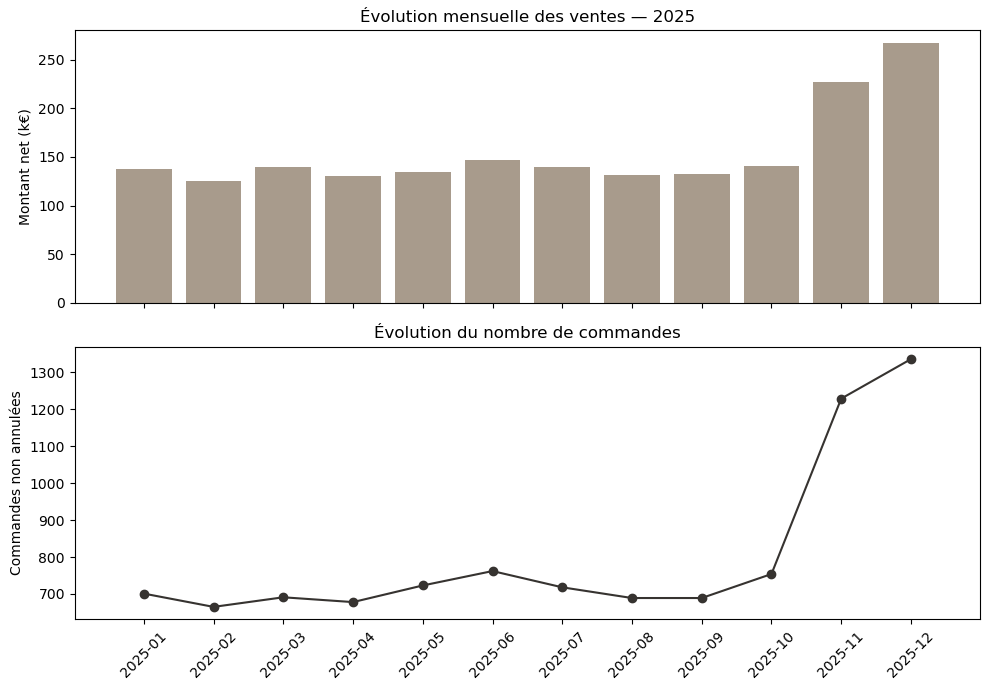

In [75]:
import matplotlib.pyplot as plt

# Préparer les libellés des mois
months = monthly_summary.index.astype(str)

# Visualiser les ventes et le nombre de commandes séparément
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].bar(
    months,
    monthly_summary["total_revenue"] / 1000,
    color="#A89B8C"
)
axes[0].set_title("Évolution mensuelle des ventes — 2025")
axes[0].set_ylabel("Montant net (k€)")

axes[1].plot(
    months,
    monthly_summary["number_of_orders"],
    marker="o",
    color="#363330"
)
axes[1].set_title("Évolution du nombre de commandes")
axes[1].set_ylabel("Commandes non annulées")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 6.2 — Contribution des canaux de vente

**Question métier :**
Quelle est la contribution de Website et Boutique aux ventes,
et comment leur panier moyen diffère-t-il ?

**KPI :** Total Revenue, Number of Orders et AOV par canal.

**Méthode :**
Comparer les commandes non annulées, après remises et remboursements.
La part des ventes précise la contribution de chaque canal au total annuel.

**Limite :**
Les coûts ne sont pas disponibles ; cette comparaison ne mesure pas
la rentabilité des canaux.

In [76]:
# Associer chaque commande non annulée à son canal et à son montant net
channel_orders = valid_orders[
    ["order_id", "sales_channel"]
].merge(
    order_amounts,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Vérifier que chaque commande possède un montant
assert channel_orders["net_line_amount"].notna().all()

# Calculer les ventes et le nombre de commandes par canal
channel_summary = channel_orders.groupby("sales_channel").agg(
    total_revenue=("net_line_amount", "sum"),
    number_of_orders=("order_id", "nunique")
)

# Calculer le panier moyen et la contribution aux ventes annuelles
channel_summary["aov"] = (
    channel_summary["total_revenue"]
    / channel_summary["number_of_orders"]
)

channel_summary["revenue_share_pct"] = (
    channel_summary["total_revenue"]
    / channel_summary["total_revenue"].sum()
    * 100
)

display(channel_summary.round(2))

,total_revenue,number_of_orders,aov,revenue_share_pct
sales_channel,,,,
Boutique,358954.5,1857,193.30,19.38
Website,1493672.5,7778,192.04,80.62


### Constats — Contribution des canaux de vente

- Website représente 80,62 % du montant net des ventes,
  avec 7 778 commandes non annulées.
- Boutique représente 19,38 % des ventes, avec 1 857 commandes.
- Les paniers moyens sont proches : 192,04 € pour Website
  et 193,30 € pour Boutique, soit un écart de 1,26 €.

**Interprétation :**
La contribution plus importante de Website repose sur le volume
de commandes, et non sur un panier moyen plus élevé.
Les données disponibles ne permettent pas de comparer
la rentabilité des deux canaux.

### 6.3 — Performance des catégories et des produits

**Question métier :**
Quelles catégories et quels produits contribuent le plus aux ventes,
et lesquels se vendent moins ?

**Indicateurs :**
Montant net des ventes, quantités commandées et quantités retournées.

**Méthode :**
Utiliser les lignes des commandes non annulées et les rattacher
au catalogue par product_id.

**Limites :**
Le montant des ventes ne mesure pas le bénéfice.
Sans données de stock et de disponibilité, de faibles ventes
ne suffisent pas à démontrer une faible demande.

In [77]:
# Associer les lignes de vente aux informations du catalogue
product_sales = sales_items.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Résumer les ventes et les quantités par catégorie
category_summary = product_sales.groupby("category").agg(
    total_revenue=("net_line_amount", "sum"),
    units_ordered=("quantity", "sum"),
    units_returned=("returned_quantity", "sum")
)

# Calculer les quantités nettes après retours
category_summary["net_units"] = (
    category_summary["units_ordered"]
    - category_summary["units_returned"]
)

# Classer les catégories selon leur contribution aux ventes
category_summary = category_summary.sort_values(
    "total_revenue", ascending=False
)

display(category_summary.round(2))

,total_revenue,units_ordered,units_returned,net_units
category,,,,
Nightwear,515950.0,3179,185,2994
Loungewear,451013.5,3076,148,2928
Bodysuits,424293.0,3175,200,2975
Bras,312275.0,3168,175,2993
Briefs,149095.5,3179,163,3016


In [78]:
# Compter toutes les catégories du catalogue
print("Nombre de catégories :", products["category"].nunique())

# Afficher le nombre de produits distincts par catégorie
display(
    products.groupby("category")["product_id"]
    .nunique()
    .rename("nombre_produits")
    .sort_values(ascending=False)
)

Nombre de catégories : 5


category
Bodysuits     40
Bras          40
Briefs        40
Loungewear    40
Nightwear     40
Name: nombre_produits, dtype: int64

### Constats — Ventes par catégorie

- Nightwear génère le montant net de ventes le plus élevé : 515 950 €.
- Briefs génère le montant le plus faible : 149 095,50 €.
- Les quantités commandées sont proches entre les catégories :
  de 3 076 à 3 179 unités.

**Interprétation :**
Le classement en valeur ne reflète pas uniquement les volumes commandés.
Il dépend également des prix, des remises et des retours.
Briefs ne peut donc pas être qualifiée de catégorie peu demandée
sur la seule base de son montant de ventes.

In [79]:
# Calculer les résultats de chaque produit vendu
product_totals = product_sales.groupby("product_id", as_index=False).agg(
    total_revenue=("net_line_amount", "sum"),
    units_ordered=("quantity", "sum"),
    units_returned=("returned_quantity", "sum")
)

# Inclure tous les produits du catalogue, même ceux sans vente
product_summary = products[
    ["product_id", "product_name", "category"]
].merge(
    product_totals,
    on="product_id",
    how="left",
    validate="one_to_one"
)

# Remplacer les totaux absents par zéro pour les produits sans vente
numeric_columns = ["total_revenue", "units_ordered", "units_returned"]
product_summary[numeric_columns] = (
    product_summary[numeric_columns].fillna(0)
)

product_summary[["units_ordered", "units_returned"]] = (
    product_summary[["units_ordered", "units_returned"]].astype(int)
)

# Afficher les cinq produits générant le plus de ventes nettes
print("Top 5 — Montant net des ventes")
display(
    product_summary.sort_values(
        ["total_revenue", "product_id"],
        ascending=[False, True]
    ).head(5).round(2)
)

# Afficher les cinq produits les moins commandés
print("Bottom 5 — Quantités commandées")
display(
    product_summary.sort_values(
        ["units_ordered", "product_id"]
    ).head(5).round(2)
)

Top 5 — Montant net des ventes


,product_id,product_name,category,total_revenue,units_ordered,units_returned
125,P0126,Aurore Nightwear 126,Nightwear,22760.5,101,4
159,P0160,Lumière Nightwear 160,Nightwear,18650.0,82,4
143,P0144,Velours Nightwear 144,Nightwear,18517.5,90,4
130,P0131,Soie Nightwear 131,Nightwear,18350.0,81,5
139,P0140,Épure Nightwear 140,Nightwear,17625.0,79,6


Bottom 5 — Quantités commandées


,product_id,product_name,category,total_revenue,units_ordered,units_returned
173,P0174,Épure Loungewear 174,Loungewear,7074.0,56,2
78,P0079,Épure Briefs 079,Briefs,1635.0,59,3
105,P0106,Aurore Bodysuits 106,Bodysuits,6480.0,59,3
92,P0093,Aurore Bodysuits 093,Bodysuits,5863.0,60,5
147,P0148,Lumière Nightwear 148,Nightwear,6825.0,60,3


In [80]:
# Afficher les 200 produits, classés par montant net des ventes
with pd.option_context("display.max_rows", 200):
    display(
        product_summary.sort_values(
            "total_revenue", ascending=False
        ).round(2)
    )

,product_id,product_name,category,total_revenue,units_ordered,units_returned
125,P0126,Aurore Nightwear 126,Nightwear,22760.5,101,4
159,P0160,Lumière Nightwear 160,Nightwear,18650.0,82,4
143,P0144,Velours Nightwear 144,Nightwear,18517.5,90,4
130,P0131,Soie Nightwear 131,Nightwear,18350.0,81,5
139,P0140,Épure Nightwear 140,Nightwear,17625.0,79,6
152,P0153,Velours Nightwear 153,Nightwear,17578.0,84,7
158,P0159,Aurore Nightwear 159,Nightwear,17400.0,82,6
149,P0150,Velours Nightwear 150,Nightwear,17352.0,78,3
145,P0146,Aurore Nightwear 146,Nightwear,17223.5,78,4
198,P0199,Aurore Loungewear 199,Loungewear,16912.5,87,1


### Constats — Performance des produits

- Les cinq produits générant le montant net de ventes le plus élevé
  appartiennent à la catégorie Nightwear.
- Aurore Nightwear 126 arrive en tête avec 22 760,50 €,
  101 unités commandées et 4 unités retournées.
- Les cinq produits les moins commandés enregistrent entre 56 et 60 unités.
  Ils appartiennent à plusieurs catégories : Loungewear, Briefs,
  Bodysuits et Nightwear.
- Aucun produit du catalogue n’est sans commande non annulée
  sur la période : le minimum observé est de 56 unités.

**Interprétation :**
La performance varie entre les modèles d’une même catégorie.
Le classement en valeur doit être distingué du classement en volume.

**Piste d’action :**
Examiner la disponibilité, la visibilité et l’ancienneté des modèles
les moins commandés avant d’envisager une promotion ou un retrait.
Ces informations ne sont pas disponibles dans cette base.

### 6.4 — Délais de service et satisfaction par motif de contact

**Question métier :**
Quels motifs de contact concentrent les difficultés de traitement,
et quel niveau de satisfaction leur est associé ?

**KPI :**
Ticket Volume, Average First Response Time, Average Resolution Time,
SLA Compliance Rate et CSAT, détaillés par contact_reason.

**Règles :**
Conserver les règles de validité définies pour les KPI globaux.
Afficher les effectifs utilisés afin de contextualiser les résultats.
Le CSAT porte uniquement sur les réponses valides aux enquêtes.

In [81]:
# Préparer une copie pour comparer les motifs de contact
service_detail = crm_analysis.copy()

# Exclure les durées de première réponse invalides des moyennes
service_detail["valid_response_hours"] = (
    service_detail["first_response_hours"].where(
        ~service_detail["first_response_date_invalid"]
        & (service_detail["first_response_hours"] >= 0)
    )
)

# Conserver uniquement les durées de résolution valides
service_detail["valid_resolution_hours"] = (
    service_detail["resolution_hours"].where(
        (service_detail["ticket_status"] == "Resolved")
        & (service_detail["resolution_hours"] >= 0)
    )
)

# Coder le SLA : 1 = conforme, 0 = non conforme, sinon valeur manquante
service_detail["sla_valid"] = service_detail["sla_status"].map({
    "Conforme": 1,
    "Non conforme": 0
})

# Préparer les réponses valides : 1 = satisfait, 0 = autre score valide
survey_detail = valid_surveys[["ticket_id", "csat_score"]].copy()
survey_detail["satisfied"] = (
    survey_detail["csat_score"].isin([4, 5]).astype(int)
)

# Ajouter les évaluations sans supprimer les tickets sans enquête
service_detail = service_detail.merge(
    survey_detail,
    on="ticket_id",
    how="left",
    validate="one_to_one"
)

# Calculer les indicateurs et leurs effectifs par motif
reason_summary = service_detail.groupby("contact_reason").agg(
    ticket_volume=("ticket_id", "size"),
    valid_responses=("valid_response_hours", "count"),
    avg_response_hours=("valid_response_hours", "mean"),
    resolved_tickets=("valid_resolution_hours", "count"),
    avg_resolution_hours=("valid_resolution_hours", "mean"),
    sla_evaluable=("sla_valid", "count"),
    sla_compliance_pct=("sla_valid", "mean"),
    survey_count=("satisfied", "count"),
    csat_pct=("satisfied", "mean")
)

# Convertir les proportions en pourcentages
reason_summary[["sla_compliance_pct", "csat_pct"]] *= 100

# Afficher les résultats par volume décroissant
with pd.option_context("display.max_columns", None):
    display(
        reason_summary.sort_values(
            "ticket_volume", ascending=False
        ).round(2)
    )

,ticket_volume,valid_responses,avg_response_hours,resolved_tickets,avg_resolution_hours,sla_evaluable,sla_compliance_pct,survey_count,csat_pct
contact_reason,,,,,,,,,
Delivery,621,611,9.40,592,23.66,611,72.01,257,83.66
Other,483,473,9.73,462,22.66,473,72.94,185,80.54
Size & Fit,392,385,8.27,377,22.30,384,76.04,151,72.19
Return & Refund,328,324,9.62,315,51.02,325,47.38,129,67.44
Product Quality,176,173,7.50,167,20.05,173,77.46,73,78.08


### Constats — Performance du service par motif

- Delivery concentre le plus grand volume : 621 tickets.
- Return & Refund présente le délai moyen de résolution le plus long :
  51,02 heures, contre environ 20 à 24 heures pour les autres motifs.
- Ce motif affiche également le respect du SLA le plus faible (47,38 %)
  et le CSAT le plus bas (67,44 %, sur 129 réponses valides).
- Son délai de première réponse (9,62 heures) est proche de celui
  de Delivery et Other : l’écart concerne surtout la résolution.
- Size & Fit présente un CSAT de 72,19 % malgré un délai moyen
  de résolution de 22,30 heures. La rapidité ne suffit donc pas
  à expliquer les différences de satisfaction entre motifs.

**Priorité à examiner :**
Étudier les étapes du processus Return & Refund pour identifier
où se situent les délais. Les données ne permettent pas encore
d’en déterminer la cause.

In [82]:
# Comparer le CSAT selon le délai de première réponse
response_comparison = service_detail.loc[
    service_detail["valid_response_hours"].notna()
    & service_detail["satisfied"].notna()
].copy()

response_comparison["response_group"] = (
    response_comparison["valid_response_hours"] > 12
).map({
    False: "Réponse ≤ 12 h",
    True: "Réponse > 12 h"
})

response_csat = response_comparison.groupby("response_group").agg(
    survey_count=("satisfied", "count"),
    csat_pct=("satisfied", "mean")
)

response_csat["csat_pct"] *= 100

# Comparer le CSAT selon le délai de résolution
resolution_comparison = service_detail.loc[
    service_detail["valid_resolution_hours"].notna()
    & service_detail["satisfied"].notna()
].copy()

resolution_comparison["resolution_group"] = (
    resolution_comparison["valid_resolution_hours"] > 48
).map({
    False: "Résolution ≤ 48 h",
    True: "Résolution > 48 h"
})

resolution_csat = resolution_comparison.groupby("resolution_group").agg(
    survey_count=("satisfied", "count"),
    csat_pct=("satisfied", "mean")
)

resolution_csat["csat_pct"] *= 100

print("CSAT selon le délai de première réponse")
display(response_csat.round(2))

print("CSAT selon le délai de résolution")
display(resolution_csat.round(2))

CSAT selon le délai de première réponse


,survey_count,csat_pct
response_group,,
Réponse > 12 h,191,74.35
Réponse ≤ 12 h,604,78.64


CSAT selon le délai de résolution


,survey_count,csat_pct
resolution_group,,
Résolution > 48 h,100,42.00
Résolution ≤ 48 h,695,82.73


### Constats — Délais et satisfaction

- Le CSAT atteint 78,64 % lorsque la première réponse intervient
  en 12 heures maximum, contre 74,35 % au-delà :
  un écart de 4,29 points de pourcentage.
- Le CSAT atteint 82,73 % lorsque la résolution intervient
  en 48 heures maximum, contre 42,00 % au-delà :
  un écart de 40,73 points de pourcentage.
- La différence observée est donc nettement plus marquée
  pour le délai de résolution.

**Interprétation :**
Dans cette simulation, les résolutions longues sont associées
à une satisfaction plus faible. Cette association ne démontre
pas une causalité et peut aussi refléter la complexité des demandes.
Les résultats concernent uniquement les réponses valides aux enquêtes.

## Phase 7 — Synthèse et recommandations

### 7.1 — Vue d’ensemble des résultats

Sur l’année 2025, les commandes non annulées représentent un montant
net de 1 852 627 €, après remises et remboursements, taxes incluses
et hors livraison.

| Indicateur | Résultat |
|---|---:|
| Total Revenue | 1 852 627 € |
| Number of Orders | 9 635 |
| AOV | 192,28 € |
| Repeat Purchase Rate | 67,05 % |
| Total Customers | 5 000 |
| Ticket Volume | 2 000 |
| CSAT | 77,61 % |
| Average First Response Time | 9,13 h |
| Average Resolution Time | 27,34 h |
| SLA Compliance Rate | 69,43 % |

**Périmètres de calcul :**
- Le taux d’achat répété porte sur les 4 140 acheteurs ayant passé
  au moins une commande non annulée ; 2 776 en ont passé au moins deux.
- Total Customers inclut toutes les fiches présentes dans l’extraction,
  dont 15 avec une date de création inconnue.
- Le CSAT repose sur 795 réponses valides, dont 617 scores de 4 ou 5.
- Le délai moyen de première réponse repose sur 1 966 tickets ;
  le délai moyen de résolution, sur 1 913 tickets résolus.
- Le SLA repose sur 1 966 tickets évaluables : 1 365 conformes
  et 601 non conformes. Les 24 tickets en attente et les 10 tickets
  indéterminés sont exclus du dénominateur.

### 7.2 — Principaux constats

#### 1. Une concentration des ventes en fin d’année

Novembre et décembre représentent ensemble 26,7 % du montant annuel
des ventes. En novembre, la progression par rapport à octobre
provient principalement de la hausse du nombre de commandes.
En décembre, le nombre de commandes et le panier moyen augmentent.

Le volume de tickets atteint également ses niveaux les plus élevés
en novembre et décembre : respectivement 310 et 367 tickets.

**Implication :** la fin d’année constitue une période importante
pour la préparation commerciale et l’organisation du service client.

#### 2. Website concentre l’essentiel des ventes

Website représente 80,62 % du montant net des ventes et 7 778 commandes,
contre 19,38 % et 1 857 commandes pour Boutique.

Les paniers moyens sont proches : 192,04 € pour Website et 193,30 €
pour Boutique. L’écart de contribution repose donc principalement
sur le volume de commandes.

**Implication :** le parcours en ligne concerne la majorité
des commandes, sans que cela permette de conclure à une meilleure
rentabilité du canal.

#### 3. La performance du catalogue diffère en valeur et en volume

Nightwear génère le montant net de ventes le plus élevé : 515 950 €.
Les cinq produits leaders en valeur appartiennent à cette catégorie.

Les quantités commandées sont cependant proches entre les catégories :
de 3 076 à 3 179 unités. Briefs présente le montant le plus faible,
mais ne peut pas être considérée comme peu demandée sur cette seule base.

Les cinq modèles les moins commandés enregistrent de 56 à 60 unités
et appartiennent à plusieurs catégories.

**Implication :** les décisions d’assortiment doivent distinguer
la contribution en euros du volume de produits commandés.

#### 4. Return & Refund constitue la principale priorité de diagnostic

Delivery génère le plus grand nombre de tickets : 621.
Return & Refund présente toutefois les résultats de service
les plus défavorables :
- délai moyen de résolution : 51,02 heures ;
- respect du SLA : 47,38 % ;
- CSAT : 67,44 %, sur 129 réponses valides.

Le délai moyen de première réponse pour Return & Refund est de 9,62 heures.
L’écart avec les autres motifs concerne surtout la durée de résolution.

Toutes raisons de contact confondues, le CSAT est de 82,73 % lorsque
la résolution intervient en 48 heures maximum, contre 42,00 % au-delà.
L’écart est de 40,73 points de pourcentage.

La différence selon le délai de première réponse est plus faible :
78,64 % en 12 heures maximum, contre 74,35 % au-delà,
soit 4,29 points de pourcentage.

**Implication :** les résolutions longues sont associées à une satisfaction
plus faible dans cette simulation. La rapidité du premier retour
ne suffit pas, à elle seule, à décrire la qualité du service.

### 7.3 — Recommandations proposées

| Axe | Action proposée | Suivi |
|---|---|---|
| Préparation de la fin d’année | Anticiper les stocks et la disponibilité du service client avant novembre ; ajuster les ressources selon la charge réelle. | Commandes, Ticket Volume, délais moyens et SLA par mois. |
| Parcours Website | Examiner le parcours de commande et l’accès au suivi de livraison et aux informations de retour, compte tenu du poids du canal. | Ventes et AOV par canal ; motifs de contact des commandes Website. |
| Assortiment | Vérifier la disponibilité des modèles leaders. Examiner les stocks, la visibilité et l’ancienneté des modèles les moins commandés avant toute promotion ou suppression. | Ventes et quantités par produit, complétées par les données de disponibilité. |
| Processus Return & Refund | Examiner les étapes entre la demande et sa résolution, identifier les attentes et les responsables, puis tester une alerte avant le seuil de 48 heures. | Délai de résolution, SLA et CSAT pour Return & Refund. |

Ces actions constituent des pistes à tester. Aucun gain financier
ni effet sur la satisfaction n’est démontré à ce stade.

### 7.4 — Limites d’interprétation

- La base Sales / CRM est entièrement synthétique.
  Les résultats illustrent une démarche analytique et des situations simulées.
- Total Revenue correspond au montant net des commandes, taxes incluses,
  et non à un chiffre d’affaires comptable HT ou à un bénéfice.
- Les remboursements sont rattachés au mois de la commande initiale,
  faute de date de remboursement.
- Les commandes non annulées encore en cours sont incluses
  dans les indicateurs commerciaux.
- Les coûts, les stocks et les dates de disponibilité des produits
  ne sont pas disponibles.
- Le CSAT décrit les réponses valides aux enquêtes, pas l’ensemble
  des clients. Un client peut évaluer plusieurs expériences de service.
- Les moyennes de délai excluent les intervalles absents ou invalides.
  Le SLA prend en compte les dépassements établis des tickets encore ouverts.
- Les associations entre délais et satisfaction ne démontrent pas
  une causalité.
- Une seule année ne permet pas de confirmer une saisonnalité récurrente.

### 7.5 — Statut du travail

**Terminé :**
- Nettoyage et contrôles des six tables.
- Calcul des dix KPI Sales / CRM.
- Analyse des quatre questions métier.
- Formulation des constats et recommandations.
